# Financial Sales Data Analysis

## Objective

The objective of this project is to analyze financial sales data, identify business trends, uncover key insights, and provide data-driven recommendations through exploratory data analysis and visualization.

## Dataset Overview

This dataset contains financial sales information across multiple countries, products, and customer segments. The analysis focuses on sales performance, profitability, and business growth opportunities.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
df = pd.read_excel("Sample data (1).xlsx")
df.head()

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,NaN,1513.0,3,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014
1,Government,Germany,Paseo,NaN,1006.0,10,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014
2,Government,Canada,Paseo,NaN,1725.0,10,350,603750.0,0.0,603750.0,448500.0,155250.0,2013-11-01,11,November,2013
3,Government,Germany,Paseo,NaN,1513.0,10,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014
4,Government,Germany,Velo,NaN,1006.0,120,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014


The dataset was successfully loaded into the notebook for analysis.

In [7]:
df.shape

(700, 16)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Segment              700 non-null    object        
 1   Country              700 non-null    object        
 2   Product              700 non-null    object        
 3   Discount Band        647 non-null    object        
 4   Units Sold           700 non-null    float64       
 5   Manufacturing Price  700 non-null    int64         
 6   Sale Price           700 non-null    int64         
 7   Gross Sales          700 non-null    float64       
 8   Discounts            700 non-null    float64       
 9    Sales               700 non-null    float64       
 10  COGS                 700 non-null    float64       
 11  Profit               700 non-null    float64       
 12  Date                 700 non-null    datetime64[ns]
 13  Month Number         700 non-null  

In [9]:
df.columns

Index(['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold',
       'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts',
       ' Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name',
       'Year'],
      dtype='object')

The dataset contains sales information across different countries, products, segments, and time periods.

In [10]:
df.isnull().sum()

Segment                 0
Country                 0
Product                 0
Discount Band          53
Units Sold              0
Manufacturing Price     0
Sale Price              0
Gross Sales             0
Discounts               0
 Sales                  0
COGS                    0
Profit                  0
Date                    0
Month Number            0
Month Name              0
Year                    0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["Discount Band"] = df["Discount Band"].fillna("None")
df.isnull().sum()

Segment                0
Country                0
Product                0
Discount Band          0
Units Sold             0
Manufacturing Price    0
Sale Price             0
Gross Sales            0
Discounts              0
 Sales                 0
COGS                   0
Profit                 0
Date                   0
Month Number           0
Month Name             0
Year                   0
dtype: int64

Missing values were handled and duplicate records were checked to ensure data quality.

In [15]:
df.describe()

,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Year
count,700.000000,700.000000,700.000000,7.000000e+02,700.000000,7.000000e+02,700.000000,700.000000,700,700.000000,700.000000
mean,1608.294286,96.477143,118.428571,1.827594e+05,13150.354629,1.696091e+05,145475.211429,24133.860371,2014-04-28 21:36:00,7.900000,2013.750000
min,200.000000,3.000000,7.000000,1.799000e+03,0.000000,1.655080e+03,918.000000,-40617.500000,2013-09-01 00:00:00,1.000000,2013.000000
25%,905.000000,5.000000,12.000000,1.739175e+04,800.320000,1.592800e+04,7490.000000,2805.960000,2013-12-24 06:00:00,5.750000,2013.750000
50%,1542.500000,10.000000,20.000000,3.798000e+04,2585.250000,3.554020e+04,22506.250000,9242.200000,2014-05-16 12:00:00,9.000000,2014.000000
75%,2229.125000,250.000000,300.000000,2.790250e+05,15956.343750,2.610775e+05,245607.500000,22662.000000,2014-09-08 12:00:00,10.250000,2014.000000
max,4492.500000,260.000000,350.000000,1.207500e+06,149677.500000,1.159200e+06,950625.000000,262200.000000,2014-12-01 00:00:00,12.000000,2014.000000
std,867.427859,108.602612,136.775515,2.542623e+05,22962.928775,2.367263e+05,203865.506118,42760.626563,NaN,3.377321,0.433322


Descriptive statistics provide an overview of sales, profit, discounts, and units sold.

## Business Question 1:
Which country generated the highest profit?

In [16]:
country_profit = df.groupby("Country")["Profit"].sum().sort_values(ascending=False)
country_profit

Country
France                      3781020.780
Germany                     3680388.820
Canada                      3529228.885
United States of America    2995540.665
Mexico                      2907523.110
Name: Profit, dtype: float64

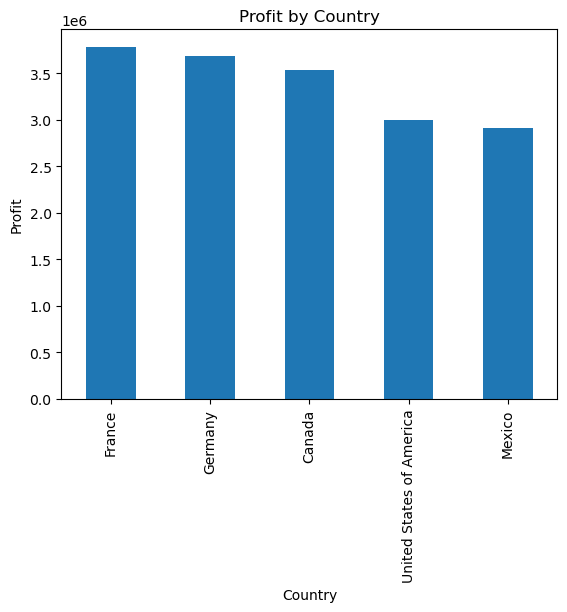

In [37]:
country_profit.plot(kind="bar")
plt.title("Profit by Country")
plt.ylabel("Profit")
plt.show()

### Key Insight:

France generated the highest profit among all countries, indicating strong business performance and market presence. This suggests that strategies used in the French market could be studied and replicated in other regions.

## Business Question 2:
Which product generated the highest profit?

In [19]:
product_profit = df.groupby("Product")["Profit"].sum().sort_values(ascending=False)
product_profit

Product
Paseo        4797437.950
VTT          3034608.020
Amarilla     2814104.060
Velo         2305992.465
Montana      2114754.880
Carretera    1826804.885
Name: Profit, dtype: float64

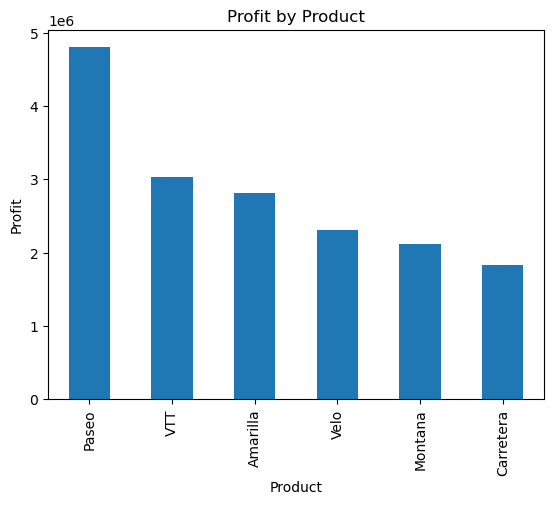

In [38]:
product_profit.plot(kind="bar")
plt.title("Profit by Product")
plt.ylabel("Profit")
plt.show()

### Key Insight:
Paseo was the most profitable product, contributing significantly to overall profit. Carretera generated the least profit and may require further analysis to improve performance.

## Business Question 3:
Which segment performed best?

In [23]:
segment_profit = df.groupby("Segment")["Profit"].sum().sort_values(ascending=False)
segment_profit

Segment
Government          1.138817e+07
Small Business      4.143168e+06
Channel Partners    1.316803e+06
Midmarket           6.601031e+05
Enterprise         -6.145456e+05
Name: Profit, dtype: float64

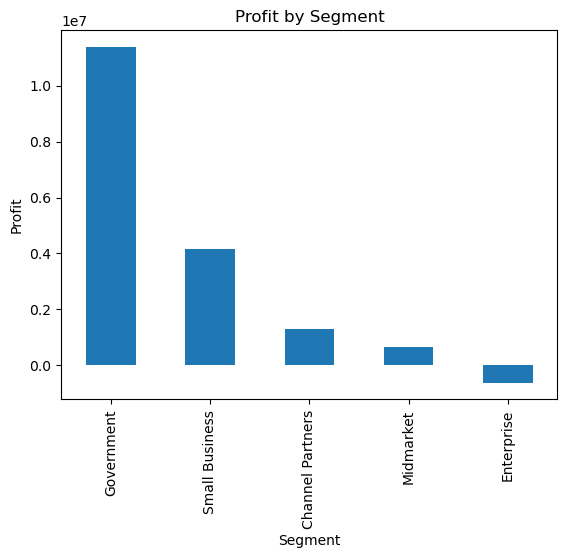

In [28]:
segment_profit.plot(kind="bar")

plt.title("Profit by Segment")
plt.ylabel("Profit")
plt.xlabel("Segment")

plt.show()

### Key Insight:

The Government segment generated the highest profit, contributing significantly to overall business performance. Small Business was the second most profitable segment. However, the Enterprise segment recorded a negative profit, indicating losses and suggesting the need for a review of pricing, discount strategies, or operational costs within that segment.

## Business Question 4:
What is the monthly sales trend?

In [33]:
monthly_sales = df.groupby("Month Name")[" Sales"].sum()
monthly_sales

Month Name
April         6964775.07
August        5864622.42
December     17367228.98
February      7297531.39
January       6607761.68
July          8102920.18
June          9518893.82
March         5586859.87
May           6210211.06
November     12651417.50
October      21671431.02
September    10882697.27
Name:  Sales, dtype: float64

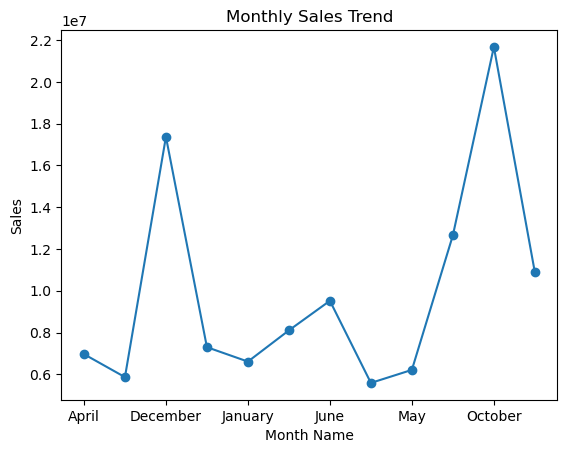

In [34]:
monthly_sales.plot(marker="o")
plt.title("Monthly Sales Trend")
plt.ylabel("Sales")
plt.show()

### Key Insight:

Sales peaked during October, indicating a period of high customer demand. Understanding the factors contributing to this increase can help improve future sales planning and marketing efforts.

## Business Question 5:
How do discount bands affect profit?

In [35]:
discount_profit = df.groupby("Discount Band")["Profit"].sum()
discount_profit

Discount Band
High      3388866.725
Low       6188857.700
Medium    5579522.835
Name: Profit, dtype: float64

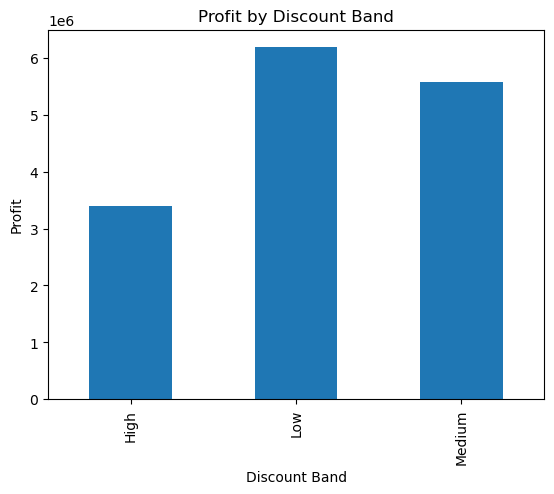

In [36]:
discount_profit.plot(kind="bar")
plt.title("Profit by Discount Band")
plt.ylabel("Profit")
plt.show()

### Key Insight:
Different discount levels have a noticeable impact on profitability. While discounts can drive sales volume, excessive discounts may reduce profit margins. Maintaining an optimal discount strategy is important for sustainable growth.

## Key Findings

1. France generated the highest overall profit.
2. Paseo was the most profitable product.
3. Government was the highest-performing segment.
4. Enterprise segment recorded a loss.
5. October recorded the highest sales, indicating a peak demand period.
6. Discount strategies had a direct impact on profitability.

## Recommendations

1. Increase focus on high-performing products such as Paseo.
2. Replicate successful strategies used in France.
3. Investigate the negative profitability of the Enterprise segment.
4. Optimize discount policies to improve profit margins.
5. Focus marketing efforts during peak sales periods.